# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:

plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')

In [3]:
plans.head()

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [4]:
users.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [5]:
usage.head()

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [6]:

print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [7]:
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [8]:
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [9]:
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [10]:

print(users.isna().sum())
print(users.isna().mean())

user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


In [11]:
print(usage.isna().sum())
print(usage.isna().mean())

id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64
id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64


✍️ **Comentario**: 
Más de 80–90% de nulos: se ignora o elimina la columna.
Entre 5% y 30%: se investiga.
Menos de 5%: imputación simple o se deja como nulo.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 
 
 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?  
- Indica qué harías: ¿imputar, eliminar, ignorar?

**Diagnóstico de valores nulos**

**users**
- `city`: 469 nulos (11.7%). Está entre 5% y 30%, así que se investiga. Además contiene el sentinel "?", que se convertirá a nulo. Se dejarán como nulos, porque imputar una ciudad podría asignar clientes al país o mercado equivocado.
- `churn_date`: 3,534 nulos (88.4%). Aunque supera el 80%, **no se elimina**: el nulo significa que el cliente sigue activo (no ha cancelado). Es información válida para analizar el churn.

**usage**
- `date`: 50 nulos (0.13%). Es menos del 5%, un caso simple: se dejan como nulos porque representan muy pocos registros.
- `duration`: 22,076 nulos (55.2%) y `length`: 17,896 nulos (44.7%). Probablemente son nulos estructurales: los mensajes no tienen duración y las llamadas no tienen longitud. Se confirmará en el paso 3.2 si dependen de la columna `type` (MAR); si es así, se dejan como nulos.

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [12]:
users.describe()

,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


In [13]:
usage.describe()

,id,user_id,duration,length
count,40000.00000,40000.000000,17924.000000,22104.000000
mean,20000.50000,12002.405975,5.202237,52.127398
std,11547.14972,1157.279564,6.842701,56.611183
min,1.00000,10000.000000,0.000000,0.000000
25%,10000.75000,10996.000000,1.437500,37.000000
50%,20000.50000,12013.000000,3.500000,50.000000
75%,30000.25000,13005.000000,6.990000,64.000000
max,40000.00000,13999.000000,120.000000,1490.000000


- Las columnas `id` y `user_id` son identificadores; no se interpretan como métricas.
- La columna `duration` no tiene valores negativos, pero hay llamadas con duración **0** (posibles llamadas no conectadas) y un máximo de **120 minutos**, muy alejado del 75% (6.99). La media (5.2) es mayor que la mediana (3.5), lo que indica sesgo a la derecha y posibles outliers.
- La columna `length` no tiene valores negativos, pero hay mensajes con longitud **0** (mensajes vacíos) y un máximo de **1,490 caracteres**, muy por encima del 75% (64). También sugiere outliers que se revisarán en el paso 5.

In [14]:

print(users['city'].value_counts(dropna=False))
print()
print(users['plan'].value_counts(dropna=False))

Bogotá      808
CDMX        730
Medellín    616
NaN         469
GDL         450
Cali        424
MTY         407
?            96
Name: city, dtype: int64

Basico     2595
Premium    1405
Name: plan, dtype: int64


- La columna `city` tiene dos problemas: el sentinel **"?"** (96 registros) y nombres **no estandarizados**. Las ciudades de Colombia aparecen completas (Bogotá, Medellín, Cali), mientras que las de México están abreviadas (CDMX, GDL, MTY). Además tiene 469 nulos.
- La columna `plan` está limpia: solo 2 categorías válidas, Basico (2,595 usuarios, ~65%) y Premium (1,405, ~35%).

In [15]:

usage['type'].value_counts(dropna=False)

text    22092
call    17908
Name: type, dtype: int64

- La columna `type` ...

- La columna `type` está limpia: solo 2 categorías, text (22,092) y call (17,908).
- Al comparar con los nulos: `duration` tiene 22,076 nulos frente a 22,092 mensajes, y `length` tiene 17,896 nulos frente a 17,908 llamadas. Esto confirma que los nulos dependen del tipo (MAR), aunque hay 28 registros que tienen ambos valores y conviene revisar.


---
✍️ **Comentario**: 
age: en describe(), un mínimo de -999 es un sentinel.
city: en value_counts(), el valor “?” también es un sentinel. 

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?  
- ¿Qué acción tomarías?

**Diagnóstico de valores inválidos y sentinels**

- `age`: sentinel **-999**. Acción: reemplazarlo por la mediana de edad (calculada sin los -999), porque es una variable clave para segmentar.
- `city`: sentinel **"?"** (96 registros). Acción: convertirlo a nulo (`pd.NA`), porque no hay forma confiable de saber la ciudad real.
- `city`: abreviaturas mexicanas (CDMX, GDL, MTY) frente a nombres completos en Colombia. Es una inconsistencia de formato; no afecta el conteo, pero conviene documentarla.
- `plan` y `type`: sin valores inválidos.

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [16]:

users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce')

In [17]:
usage['date'] = pd.to_datetime(usage['date'], errors='coerce')

In [18]:
users['reg_date'].dt.year.value_counts().sort_index()

2022    1314
2023    1316
2024    1330
2026      40
Name: reg_date, dtype: int64

En `reg_date`, los registros se distribuyen de forma pareja entre 2022 (1,314), 2023 (1,316) y 2024 (1,330). Sin embargo, aparecen **40 registros con año 2026**, una fecha imposible porque los datos llegan hasta 2024. Representan el 1% de los usuarios.

In [19]:
usage['date'].dt.year.value_counts().sort_index()

2024.0    39950
Name: date, dtype: int64


En `date`, todos los registros válidos corresponden a **2024** (39,950). No hay años fuera de rango; los 50 registros restantes son fechas vacías (NaT). El año aparece como `2024.0` porque la columna tiene nulos y pandas lo guarda como decimal.
Basaremos el análisis en estas fechas.


✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos) Como los datos llegan hasta 2024, cualquier año posterior es una fecha imposible.
- ¿Qué harías con ellas?

**Diagnóstico de fechas**

- `reg_date`: sí hay años imposibles. **40 usuarios tienen fecha de registro en 2026**, un año posterior al corte de los datos (2024). Acción: marcarlas como nulas (`pd.NA`) en el paso 3. No se eliminan los usuarios, porque el resto de su información (edad, ciudad, plan y uso) sigue siendo válida.
- `date`: no hay años imposibles; todo el uso corresponde a 2024. Los 50 registros sin fecha se dejan como nulos, porque representan solo el 0.13% de los datos.


---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [20]:

# Reemplazar -999 por la mediana de age
age_mediana = users.loc[users['age'] != -999, 'age'].median()
users['age'] = users['age'].replace(-999, age_mediana)

# Verificar cambios
users['age'].describe()

count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [21]:
# Reemplazar ? por NA en city
users['city'] = users['city'].replace('?', pd.NA)

# Verificar cambios
print(users['city'].value_counts(dropna=False))

Bogotá      808
CDMX        730
Medellín    616
NaN         565
GDL         450
Cali        424
MTY         407
Name: city, dtype: int64


In [22]:
# Marcar fechas futuras como NA para reg_date
# Nota: se usa pd.NaT porque es el valor nulo nativo para fechas; pd.NA genera error en columnas datetime
users.loc[users['reg_date'].dt.year > 2024, 'reg_date'] = pd.NaT

# Verificar cambios
print(users['reg_date'].dt.year.value_counts().sort_index())
print("Fechas nulas:", users['reg_date'].isna().sum())

2022.0    1314
2023.0    1316
2024.0    1330
Name: reg_date, dtype: int64
Fechas nulas: 40


### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [23]:
# Verificación MAR en usage (Missing At Random) para duration
usage['duration'].isna().groupby(usage['type']).mean()


type
call    0.000000
text    0.999276
Name: duration, dtype: float64

In [24]:
# Verificación MAR en usage (Missing At Random) para length
usage['length'].isna().groupby(usage['type']).mean()

type
call    0.99933
text    0.00000
Name: length, dtype: float64

**Diagnóstico de nulos en `duration` y `length`**

- `duration`: 0% de nulos en llamadas (`call`) y 99.9% en mensajes (`text`).
- `length`: 99.9% de nulos en llamadas (`call`) y 0% en mensajes (`text`).

Los nulos son **MAR**: dependen completamente de la columna `type`. Un mensaje no tiene duración y una llamada no tiene longitud de texto, así que no son errores de captura. **Se dejan como nulos**, porque imputarlos crearía llamadas o mensajes que no existen y distorsionaría el análisis.

El 0.1% restante corresponde a 28 registros con ambos valores llenos (≈16 mensajes con duración y ≈12 llamadas con longitud). Es una inconsistencia menor que se documenta, pero no afecta el análisis.

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [25]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas


# Agrupar información por usuario
usage_agg = usage.groupby('user_id').agg({
    'is_text': 'sum',
    'is_call': 'sum',
    'duration': 'sum'
}).reset_index()

# observar resultado
usage_agg.head(3)

,user_id,is_text,is_call,duration
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [26]:
# Renombrar columnas
usage_agg = usage_agg.rename(columns={
    'is_text': 'cant_mensajes',
    'is_call': 'cant_llamadas',
    'duration': 'cant_minutos_llamada'
})

# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [27]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = users.merge(usage_agg, on='user_id', how='left')
user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [28]:
# Resumen estadístico de las columnas numéricas
user_profile[['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']].describe()


,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,3999.000000,3999.000000,3999.000000
mean,48.136000,5.524381,4.478120,23.317054
std,17.689919,2.358416,2.144238,18.168095
min,18.000000,0.000000,0.000000,0.000000
25%,33.000000,4.000000,3.000000,11.120000
50%,48.000000,5.000000,4.000000,19.780000
75%,63.000000,7.000000,6.000000,31.415000
max,79.000000,17.000000,15.000000,155.690000


In [29]:
# Distribución porcentual del tipo de plan
user_profile['plan'].value_counts(normalize=True) * 100


Basico     64.875
Premium    35.125
Name: plan, dtype: float64

**Observaciones del resumen por usuario (2024)**

- `count`: 3,999 usuarios tienen uso registrado; **1 usuario no registró llamadas ni mensajes** (queda como nulo tras el merge).
- `cant_mensajes`: mediana de 5 mensajes por usuario (rango 0–17).
- `cant_llamadas`: mediana de 4 llamadas por usuario (rango 0–15).
- `cant_minutos_llamada`: mediana de 19.8 minutos, pero el máximo llega a **155.7 minutos**, muy por encima del 75% (31.4). La media (23.3) es mayor que la mediana, lo que indica **sesgo a la derecha** y posibles outliers.
- `plan`: **64.9% Básico** y **35.1% Premium**.

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

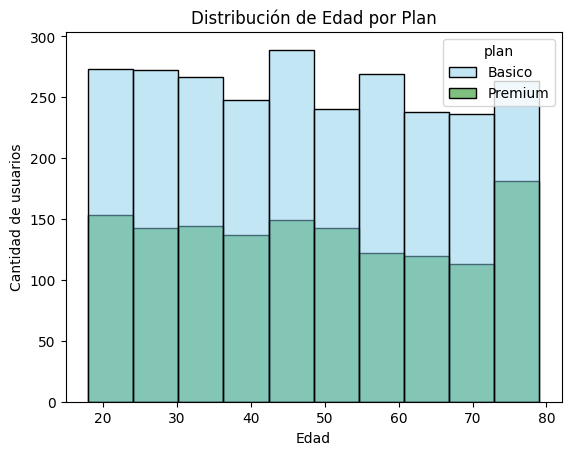

In [30]:
# Histograma para visualizar la edad (age)
sns.histplot(data=user_profile, x='age', hue='plan', palette=['skyblue', 'green'], bins=10)
plt.title('Distribución de Edad por Plan')
plt.xlabel('Edad')
plt.ylabel('Cantidad de usuarios')
plt.show()

💡 **Insights:**

- **Distribución aproximadamente uniforme (plana)**: hay usuarios de todas las edades entre 18 y 79 años en cantidades similares, sin un grupo dominante.
- En el plan **Básico** la distribución es pareja (≈240–290 usuarios por rango).
- En el plan **Premium** destaca el grupo de **mayor edad (75–79 años)**, con la mayor concentración de usuarios Premium (≈180), lo que sugiere que los clientes mayores tienden a contratar el plan más completo.
- El ligero pico alrededor de 45–50 años en Básico puede deberse a la imputación de los -999 con la mediana (48).

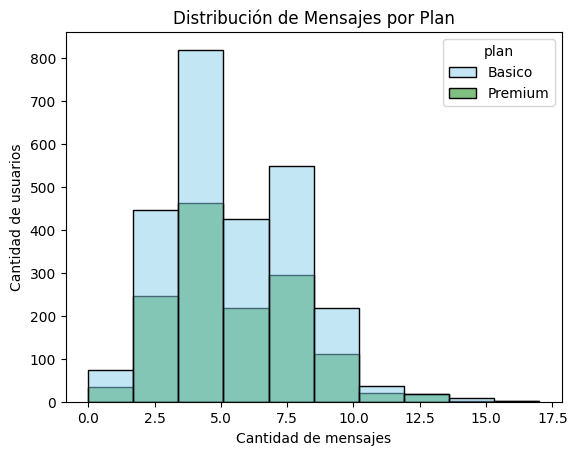

In [31]:
# Histograma para visualizar la cant_mensajes
sns.histplot(data=user_profile, x='cant_mensajes', hue='plan', palette=['skyblue', 'green'], bins=10)
plt.title('Distribución de Mensajes por Plan')
plt.xlabel('Cantidad de mensajes')
plt.ylabel('Cantidad de usuarios')
plt.show()


💡 **Insights:**

- **Distribución ligeramente sesgada a la derecha**: la mayoría de los usuarios envía entre **3 y 8 mensajes**, con una cola de pocos usuarios que llegan a 15–17.
- Los usuarios **Básico y Premium muestran el mismo patrón**: el plan Premium no se traduce en mayor envío de mensajes.
- El uso real está **muy por debajo de lo incluido en los planes** (100 mensajes en Básico y 500 en Premium), lo que indica que el beneficio de mensajes está sobredimensionado.

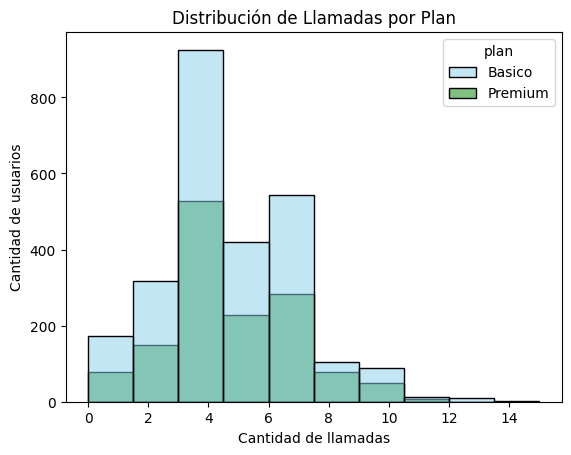

In [32]:
# Histograma para visualizar la cant_llamadas
sns.histplot(data=user_profile, x='cant_llamadas', hue='plan', palette=['skyblue', 'green'], bins=10)
plt.title('Distribución de Llamadas por Plan')
plt.xlabel('Cantidad de llamadas')
plt.ylabel('Cantidad de usuarios')
plt.show()

💡 **Insights:**

- **Distribución ligeramente sesgada a la derecha**: la mayoría de los usuarios realiza entre **3 y 7 llamadas**, con el pico en 3–4 llamadas y una cola hasta 15.
- **No existe una diferencia clara entre planes**: Básico y Premium tienen una forma de distribución casi idéntica.
- Hay pocos usuarios con 10 o más llamadas, que podrían ser outliers a revisar en los boxplots.

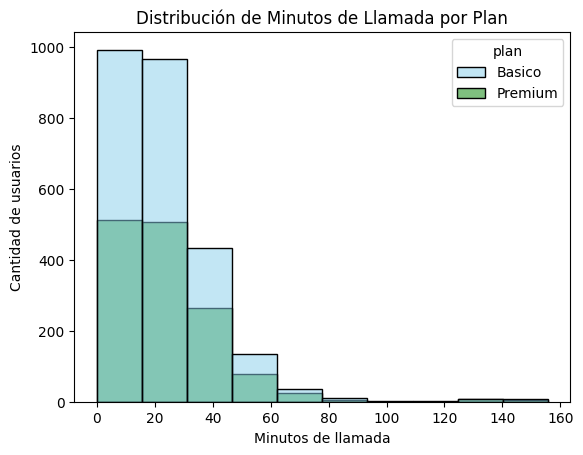

In [33]:
# Histograma para visualizar la cant_minutos_llamada
sns.histplot(data=user_profile, x='cant_minutos_llamada', hue='plan', palette=['skyblue', 'green'], bins=10)
plt.title('Distribución de Minutos de Llamada por Plan')
plt.xlabel('Minutos de llamada')
plt.ylabel('Cantidad de usuarios')
plt.show()

💡 **Insights:**

- **Distribución claramente sesgada a la derecha**: la gran mayoría de los usuarios acumula **entre 0 y 30 minutos** de llamada, y la frecuencia cae rápidamente después de 40 minutos.
- Existe una **cola larga con pocos usuarios entre 120 y 155 minutos**, posibles outliers por uso intensivo.
- **El patrón es similar en ambos planes**: los usuarios Premium no consumen más minutos que los Básico, aunque su plan incluye 600 minutos frente a 100.
- Los pocos usuarios que superan los 100 minutos sí rebasan el límite del plan Básico, y son candidatos naturales para **migrar a Premium**.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

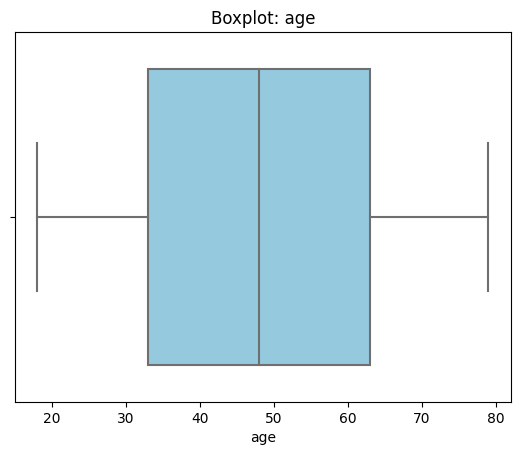

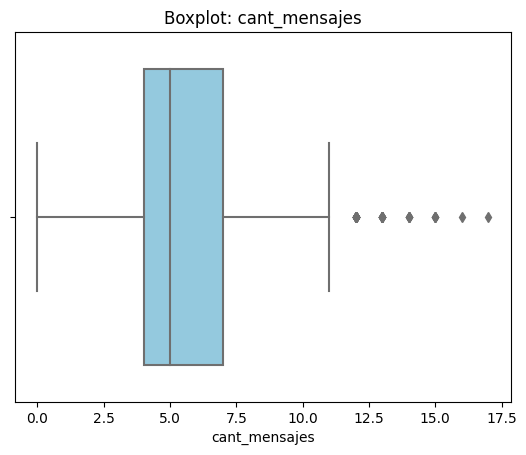

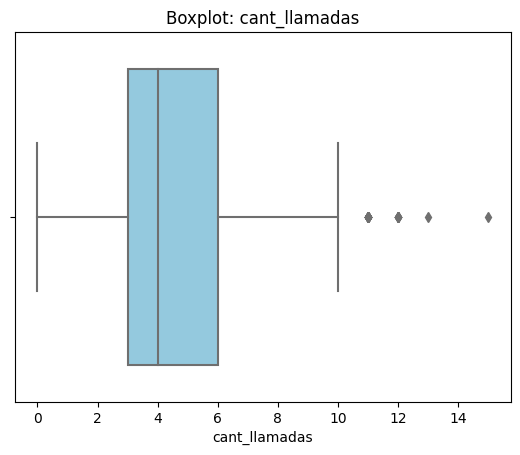

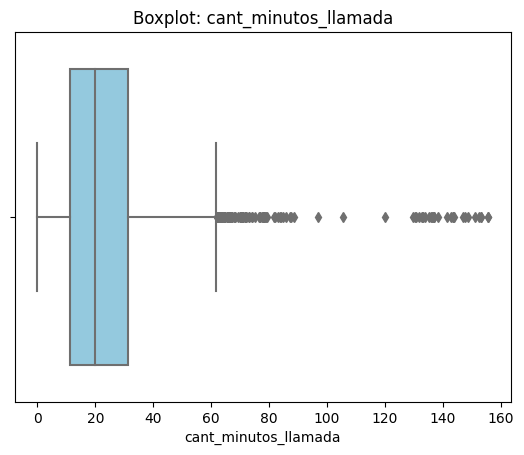

In [34]:
# Visualizando usando BoxPlot
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    sns.boxplot(x=user_profile[col], color='skyblue')
    plt.title(f'Boxplot: {col}')
    plt.xlabel(col)
    plt.show()


💡 **Insights:**

- **age**: **no presenta outliers**. Todos los valores están dentro de los bigotes (18 a 79 años) y la caja es amplia y centrada (mediana 48), lo que confirma la distribución uniforme vista en el histograma.
- **cant_mensajes**: **sí presenta outliers**, solo del lado derecho. Hay usuarios con **12 a 17 mensajes**, por encima del bigote superior (~11).
- **cant_llamadas**: **sí presenta outliers**, solo del lado derecho. Unos pocos usuarios tienen **11, 12, 13 y 15 llamadas**, por encima del bigote superior (10).
- **cant_minutos_llamada**: **presenta la mayor cantidad de outliers**, todos del lado derecho. Hay muchos usuarios entre **62 y 100 minutos** y además un **grupo separado entre 120 y 155 minutos**, muy alejado del resto.

In [35]:
# Calcular límites con el método IQR
columnas_limites = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_limites:
    Q1 = user_profile[col].quantile(0.25)
    Q3 = user_profile[col].quantile(0.75)
    IQR = Q3 - Q1
    limite_superior = Q3 + 1.5 * IQR
    print(f"{col}: límite superior = {limite_superior}")

cant_mensajes: límite superior = 11.5
cant_llamadas: límite superior = 10.5
cant_minutos_llamada: límite superior = 61.8575


In [36]:
user_profile[columnas_limites].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,3999.000000,3999.000000,3999.000000
mean,5.524381,4.478120,23.317054
std,2.358416,2.144238,18.168095
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.120000
50%,5.000000,4.000000,19.780000
75%,7.000000,6.000000,31.415000
max,17.000000,15.000000,155.690000


💡 **Insights:**

- **cant_mensajes** (límite superior 11.5, máximo 17): **se mantienen los outliers**. Son valores realistas (enviar 17 mensajes no es un error) y siguen muy por debajo de lo incluido en cualquier plan. Representan a usuarios algo más activos, no a datos incorrectos.
- **cant_llamadas** (límite superior 10.5, máximo 15): **se mantienen los outliers**. Son pocos usuarios con un uso un poco mayor al promedio; no hay valores negativos ni imposibles, por lo que reflejan comportamiento real.
- **cant_minutos_llamada** (límite superior 61.9, máximo 155.7): **se mantienen, pero se marcan para revisión**. Los valores entre 62 y 100 minutos son usuarios intensivos plausibles. El **grupo de 120–155 minutos**, separado del resto, merece atención: puede tratarse de clientes de alto consumo (candidatos a migrar a Premium, ya que superan los 100 minutos del plan Básico) o de un posible uso anómalo que convendría verificar con el área de fraude.

**Decisión general:** no se eliminan outliers. No son errores de captura y aportan información valiosa para la segmentación y para detectar oportunidades comerciales.

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [37]:
# Crear columna grupo_uso
# Usuarios sin registros de uso: se considera 0 llamadas, 0 mensajes y 0 minutos
cols_uso = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']
user_profile[cols_uso] = user_profile[cols_uso].fillna(0)

user_profile['grupo_uso'] = np.where(
    (user_profile['cant_llamadas'] < 5) & (user_profile['cant_mensajes'] < 5), 'Bajo uso',
    np.where(
        (user_profile['cant_llamadas'] < 10) & (user_profile['cant_mensajes'] < 10), 'Uso medio',
        'Alto uso'
    )
)

In [38]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [39]:
# Crear columna grupo_edad
user_profile['grupo_edad'] = np.where(
    user_profile['age'] < 30, 'Joven',
    np.where(user_profile['age'] < 60, 'Adulto', 'Adulto Mayor')
)

In [40]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

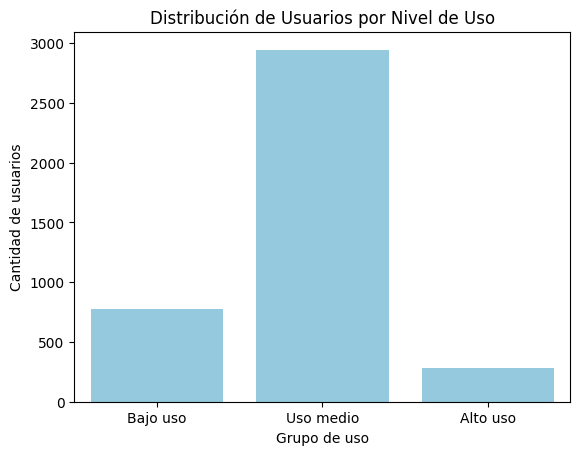

In [41]:
# Visualización de los segmentos por uso
sns.countplot(data=user_profile, x='grupo_uso', order=['Bajo uso', 'Uso medio', 'Alto uso'], color='skyblue')
plt.title('Distribución de Usuarios por Nivel de Uso')
plt.xlabel('Grupo de uso')
plt.ylabel('Cantidad de usuarios')
plt.show()

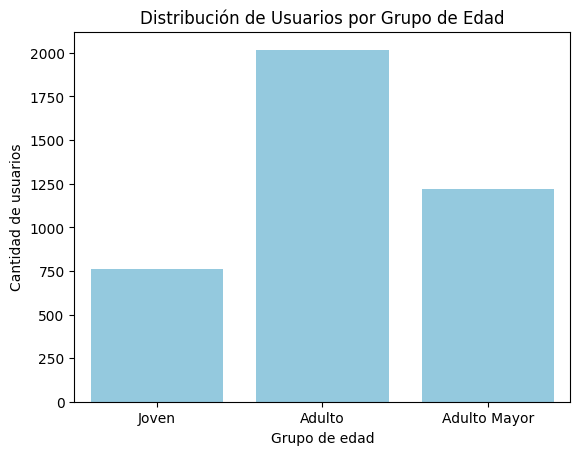

In [42]:
# Visualización de los segmentos por edad
sns.countplot(data=user_profile, x='grupo_edad', order=['Joven', 'Adulto', 'Adulto Mayor'], color='skyblue')
plt.title('Distribución de Usuarios por Grupo de Edad')
plt.xlabel('Grupo de edad')
plt.ylabel('Cantidad de usuarios')
plt.show()

In [43]:
# Proporción de cada grupo de uso dentro de cada grupo de edad (%)
print(pd.crosstab(user_profile['grupo_edad'], user_profile['grupo_uso'], normalize='index') * 100)
print()
# Proporción de plan dentro de cada grupo de edad (%)
print(pd.crosstab(user_profile['grupo_edad'], user_profile['plan'], normalize='index') * 100)

grupo_uso     Alto uso   Bajo uso  Uso medio
grupo_edad                                  
Adulto        7.581764  18.087215  74.331021
Adulto Mayor  6.055646  21.031097  72.913257
Joven         6.710526  20.657895  72.631579

plan             Basico    Premium
grupo_edad                        
Adulto        65.659068  34.340932
Adulto Mayor  64.157119  35.842881
Joven         63.947368  36.052632



---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**

- `age`: el sentinel **-999** afectaba a ≈55 usuarios (1.4%) y distorsionaba la media (33.7 años frente a 48 reales). Se reemplazó por la mediana (48).
- `city`: **469 nulos (11.7%)** más **96 registros con "?" (2.4%)**, en total **565 sin ciudad (14.1%)**. Se dejaron como nulos. Además, las ciudades de México están abreviadas (CDMX, GDL, MTY) y las de Colombia no.
- `reg_date`: **40 usuarios (1%) con fecha de registro en 2026**, posterior al corte de datos. Se marcaron como nulas.
- `usage`: **50 registros sin fecha (0.13%)**. Los nulos de `duration` y `length` son estructurales (MAR por tipo) y se dejaron como nulos; 28 registros tienen ambos valores llenos.
- `churn_date`: 88% de nulos, que no son error: indican clientes activos. 1 usuario no registró uso.

🔍 **Segmentos por Edad**

- **Adulto (30–59 años): ~50%** de los clientes, el segmento principal.
- **Adulto Mayor (60+): ~30%** y **Joven (<30): ~19%**.
- Los tres grupos tienen **comportamiento de uso y mezcla de planes muy similares** (≈73% uso medio y ≈65% Básico en todos).

📊 **Segmentos por Nivel de Uso**

- **Uso medio: ~73%**, **Bajo uso: ~20%** y **Alto uso: ~7%**.
- Los usuarios **Premium no consumen más que los Básico**: las distribuciones de llamadas, mensajes y minutos son prácticamente iguales en ambos planes.
- Hay **outliers de alto consumo de minutos**, con un grupo separado entre **120 y 155 minutos**, muy por encima de la mediana (19.8 minutos).


💎 **Segmentos más valiosos**

- **Premium (35% de los clientes):** generan el mayor ingreso por usuario (USD 25 frente a 12 al mes). Son prioridad de retención, porque hoy no aprovechan los beneficios que pagan.
- **Básico de Alto uso:** son los más propensos a necesitar un plan superior, así que representan la mayor oportunidad de crecimiento de ingresos (upgrade a Premium).
- **Adultos de 30–59 años:** son la mitad de la base de clientes; cualquier ajuste en los planes debe pensarse primero para ellos.

➡️ **Esto sugiere que** los planes actuales están **sobredimensionados** frente al uso real. La mediana de uso en todo 2024 (5 mensajes, 4 llamadas y ~20 minutos) queda muy por debajo de lo incluido **cada mes** en el plan Básico (100 mensajes y 100 minutos), y aún más en Premium (500 mensajes y 600 minutos). Además, el plan Premium no se diferencia por mayor consumo, lo que pone en duda su valor percibido.

💡 **Recomendaciones**

- **Crear un plan de entrada más económico** para el ~20% de Bajo uso, con menos minutos y mensajes incluidos a un precio menor, para atraer clientes sensibles al precio.
- **Revisar la propuesta de valor de Premium**: el 35% de los clientes paga más sin consumir más. Conviene agregar beneficios distintos al volumen (más datos, roaming entre México y Colombia, atención preferente); de lo contrario existe riesgo de churn o de bajada de plan.
- **Ofrecer upgrade dirigido** a los usuarios Básico de Alto uso y a los que superan los 100 minutos: son los únicos que realmente se acercan al límite de su plan.
- **Investigar el grupo de 120–155 minutos** con el área de fraude, para confirmar si se trata de clientes intensivos legítimos o de un uso anómalo.
- **Mejorar la captura de datos**: validar edad y fecha de registro al dar de alta un cliente, y estandarizar los nombres de ciudades, para evitar sentinels y fechas imposibles en el futuro.


---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`